**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [34]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [35]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

100%|██████████| 734k/734k [00:00<00:00, 1.53MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/iammustafatz/diabetes-prediction-dataset/versions/1


In [36]:
import os
import pandas as pd

df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [37]:
# TODO: виведіть df.info() і коротко прокоментуйте типи даних.

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


У датасеті представлені категоріальні ознаки типу object (gender, smoking_history), які потребують кодування перед використанням у моделях, цілочисельні показники та бінарні прапорці типу int64 (hypertension, heart_disease, diabetes), а також неперервні медичні метрики типу float64 (bmi, HbA1c_level, blood_glucose_level)

Провести дослідження категоріальних ознак

In [38]:
# TODO: підрахуйте частоти категорій у gender.

df["gender"].value_counts()

,count
gender,
Female,58552
Male,41430
Other,18


In [39]:
# TODO: підрахуйте частоти категорій у smoking_history.

df["smoking_history"].value_counts()

,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


In [40]:
# TODO: df

df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести типи даних

In [41]:
# TODO: df.dtypes

df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [42]:
# TODO: df['diabetes'].value_counts()

df["diabetes"].value_counts()

,count
diabetes,
0,91500
1,8500


Висновок: визначте за результатом, чи є дисбаланс класів.

За результатами підрахунку спостережується виражений дисбаланс класів, оскільки переважна більшість об'єктів належить до класу 0 (здорові пацієнти), тоді як клас 1 (пацієнти з діабетом) становить лише декілька відсотків від загальної вибірки, що вимагає використання спеціальних метрик (Precision, Recall, F1-score, ROC-AUC) та методів балансування даних при навчанні моделей.

Перевірити наявність пропущених даних


In [43]:
# TODO: df.isnull().sum()

df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [44]:
# TODO: df.duplicated().sum()

df.duplicated().sum()

np.int64(3854)

Видалити дублікати

In [45]:
# TODO: df.drop_duplicates(inplace=True)

df.drop_duplicates(inplace=True)

In [46]:
# TODO: df

df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [47]:
# TODO: df['diabetes'].value_counts()\

df["diabetes"].value_counts()

,count
diabetes,
0,87664
1,8482


Побудувати гістограму для цільової змінної


<Axes: xlabel='diabetes', ylabel='count'>

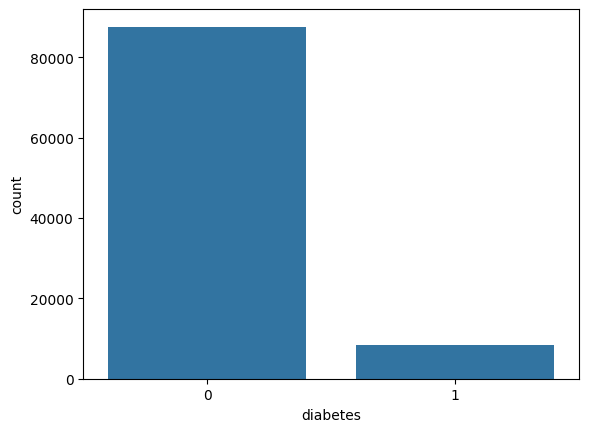

In [48]:
# TODO: sns.countplot(x='diabetes', data=df, color='tab:blue')

import seaborn as sns

sns.countplot(x='diabetes', data=df, color='tab:blue')

Переглянути описові статистики **навчальної вибірки**

In [49]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [50]:
# TODO: створіть X та y, де y — стовпець diabetes.
# TODO: поділіть X та y на train і test у пропорції 80/20.
# Використайте random_state=42 та stratify=y.

# Описова статистика
print(df.describe())

# Підготовка даних та розділення на train/test
X = df.drop(columns=['diabetes'])
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

                age  hypertension  heart_disease           bmi   HbA1c_level  \
count  96146.000000  96146.000000   96146.000000  96146.000000  96146.000000   
mean      41.794326      0.077601       0.040803     27.321461      5.532609   
std       22.462948      0.267544       0.197833      6.767716      1.073232   
min        0.080000      0.000000       0.000000     10.010000      3.500000   
25%       24.000000      0.000000       0.000000     23.400000      4.800000   
50%       43.000000      0.000000       0.000000     27.320000      5.800000   
75%       59.000000      0.000000       0.000000     29.860000      6.200000   
max       80.000000      1.000000       1.000000     95.690000      9.000000   

       blood_glucose_level      diabetes  
count         96146.000000  96146.000000  
mean            138.218231      0.088220  
std              40.909771      0.283616  
min              80.000000      0.000000  
25%             100.000000      0.000000  
50%             140.0

Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [51]:
# TODO: використайте pd.get_dummies для gender та smoking_history.
# TODO: закодуйте X_train та X_test.
# TODO: вирівняйте стовпці X_test за X_train через reindex(..., fill_value=0).

X = df.drop(columns=['diabetes'])
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train = pd.get_dummies(X_train, columns=['gender', 'smoking_history'], drop_first=True)
X_test = pd.get_dummies(X_test, columns=['gender', 'smoking_history'], drop_first=True)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [52]:
# TODO: виведіть статистики опису X_train.

X_train.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [53]:
# TODO: обчисліть кореляцію X_train із y_train (не використовуйте df або y_test).

X_train.corrwith(y_train)

,0
age,0.266649
hypertension,0.199069
heart_disease,0.174470
bmi,0.213456
HbA1c_level,0.405321
blood_glucose_level,0.423011
gender_Male,0.040650
gender_Other,-0.004197
smoking_history_current,0.013508
smoking_history_ever,0.020899


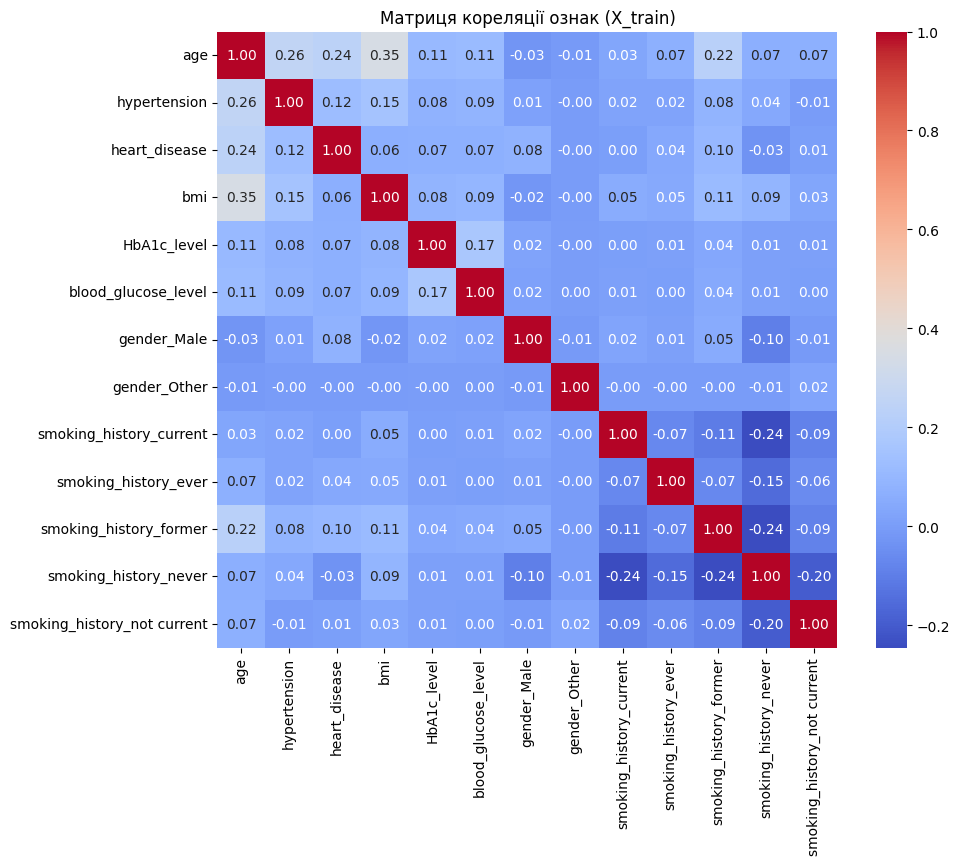

In [54]:
# TODO: обчисліть матрицю кореляції ознак X_train.
# TODO: побудуйте теплову карту (sns.heatmap).

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))
sns.heatmap(X_train.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Матриця кореляції ознак (X_train)")
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Найсильніше з цільовою змінною корелюють рівень глюкози в крові (blood_glucose_level), рівень глікованого гемоглобіну (HbA1c_level), а також вік (age) та індекс маси тіла (bmi), тоді як між самими ознаками високої мультиколінеарності (значень $r > 0.8$) не спостерігається. Видаляти ознаки на даному етапі не потрібно, оскільки відсутня критична мультиколінеарність між фічами, а лінійні та деревні моделі зможуть ефективно використати всі наявні медичні параметри для покращення якості класифікації.

Перевірити викиди **лише на навчальній вибірці**

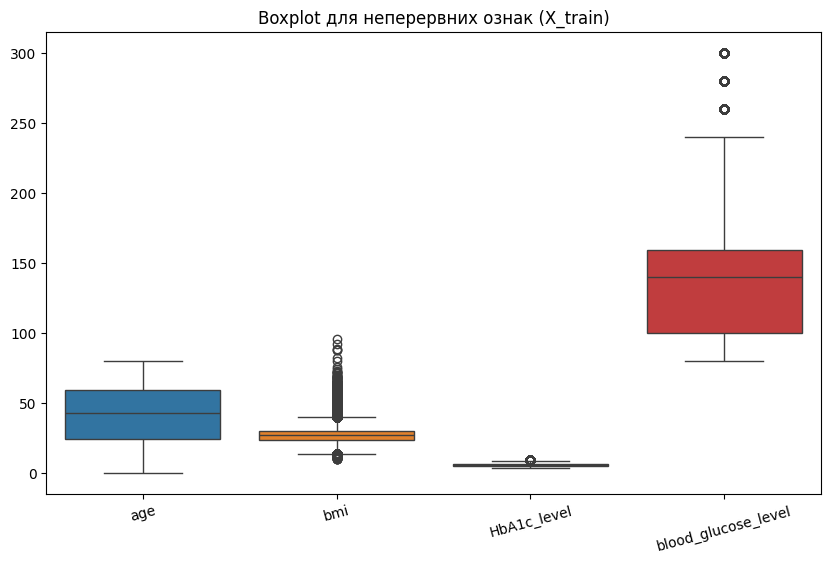

In [55]:
# TODO: задайте continuous_cols для age, bmi, HbA1c_level, blood_glucose_level.
# TODO: побудуйте boxplot за X_train[continuous_cols], НЕ за df.

import matplotlib.pyplot as plt
import seaborn as sns

continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

plt.figure(figsize=(10, 6))
sns.boxplot(data=X_train[continuous_cols])
plt.title("Boxplot для неперервних ознак (X_train)")
plt.xticks(rotation=15)
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [56]:
# НЕОБОВ'ЯЗКОВО: опишіть, як обчислити IQR для bmi тільки на X_train.
# Якщо вирішите вилучати рядки, синхронно оновіть X_train та y_train.
# Тестові дані не змінюйте. У цій роботі викиди не видаляємо.

Перевірити асиметрію розподілів ознак **на train**

In [57]:
# TODO: знайдіть асиметрію розподілів X_train[continuous_cols].

X_train[continuous_cols].skew()

,0
age,-0.061461
bmi,1.005016
HbA1c_level,-0.055651
blood_glucose_level,0.830778


In [58]:
# TODO: перевірте пропуски окремо в X_train та X_test.

print("Пропуски в X_train:")
print(X_train.isnull().sum())

print("\nПропуски в X_test:")
print(X_test.isnull().sum())

Пропуски в X_train:
age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Male                    0
gender_Other                   0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking_history_never          0
smoking_history_not current    0
dtype: int64

Пропуски в X_test:
age                            0
hypertension                   0
heart_disease                  0
bmi                            0
HbA1c_level                    0
blood_glucose_level            0
gender_Male                    0
gender_Other                   0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking_history_never          0
smoking_history_not current    0
dtype: int64


**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

За результатами аналізу навчальної вибірки (X_train) виявлено суттєвий дисбаланс цільової змінної з перевагою негативного класу, відсутність критичної мультиколінеарності між ознаками (найсильніша кореляція з цільовою змінною спостерігається для blood_glucose_level та HbA1c_level), а також наявність правосторонньої асиметрії й зафіксованих викидів у показниках bmi, HbA1c_level та blood_glucose_level, які відповідають реалістичним медичним станам і не потребують вилучення.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [59]:
# TODO: створіть StandardScaler.
# TODO: виконайте fit_transform на X_train і transform на X_test.

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [60]:
# TODO: збалансуйте тільки масштабовану навчальну вибірку методом SMOTE.
# TODO: порівняйте кількості класів до та після балансування.

from imblearn.over_sampling import SMOTE

# Застосування SMOTE лише до навчальної вибірки
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

# Порівняння розподілу класів
print("Розподіл класів до SMOTE:\n", y_train.value_counts())
print("\nРозподіл класів після SMOTE:\n", y_train_resampled.value_counts())

Розподіл класів до SMOTE:
 diabetes
0    70130
1     6786
Name: count, dtype: int64

Розподіл класів після SMOTE:
 diabetes
0    70130
1    70130
Name: count, dtype: int64


Оголошуємо моделі

In [61]:
# TODO: створіть словник models для чотирьох моделей:
# LogisticRegression, RidgeClassifier, SGDClassifier, SVC.
# Для відтворюваності вкажіть random_state=42, де це передбачено.

models = {
    'LogisticRegression': LogisticRegression(random_state=42),
    'RidgeClassifier': RidgeClassifier(random_state=42),
    'SGDClassifier': SGDClassifier(random_state=42),
    'SVC': SVC(random_state=42)
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт


=== LogisticRegression ===
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.89      0.90     19230



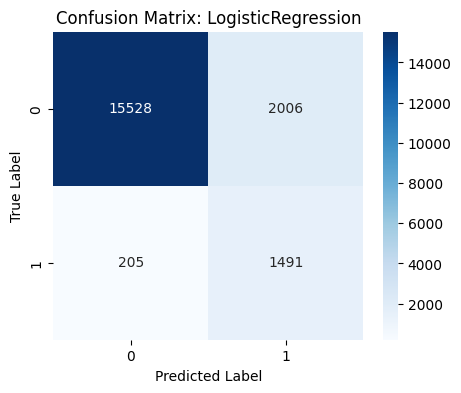

=== RidgeClassifier ===
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



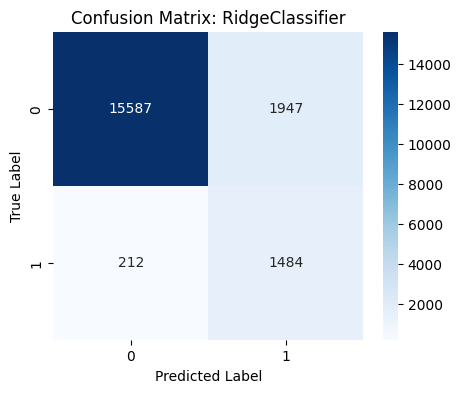

=== SGDClassifier ===
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.53      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



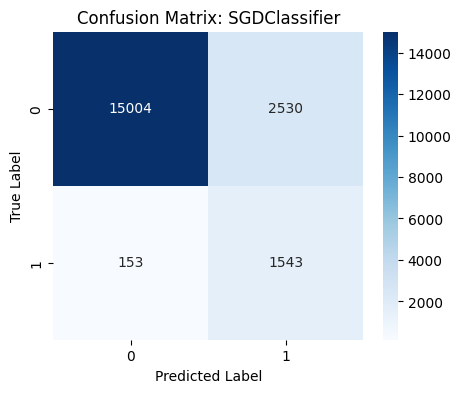

=== SVC ===
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230



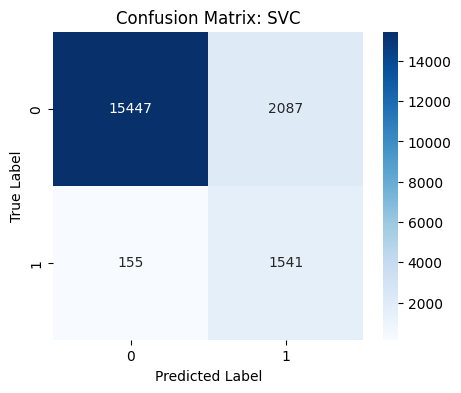

In [62]:
# TODO: навчіть кожну модель на збалансованій навчальній вибірці.
# TODO: зробіть прогноз на масштабованій X_test.
# TODO: виведіть classification_report та confusion_matrix (теплова карта).

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

for name, model in models.items():
    # Навчання моделі на збалансованій навчальній вибірці
    model.fit(X_train_resampled, y_train_resampled)

    # Прогноз на масштабованій тестовій вибірці
    y_pred = model.predict(X_test_scaled)

    # Вивід текстового звіту
    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred))

    # Побудова матриці плутанини
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.show()

Оптимізувати гіперпараметри


In [63]:
# TODO: задайте словник param_grids для кожної моделі.
# Приклади: C та solver; alpha; loss та penalty; C та kernel.

from sklearn.model_selection import GridSearchCV

# Словник сіток гіперпараметрів для кожної моделі
param_grids = {
    'LogisticRegression': {
        'C': [0.01, 0.1, 1, 10],
        'solver': ['lbfgs', 'liblinear']
    },
    'RidgeClassifier': {
        'alpha': [0.1, 1.0, 10.0, 100.0]
    },
    'SGDClassifier': {
        'loss': ['hinge', 'log_loss'],
        'penalty': ['l2', 'l1'],
        'alpha': [0.0001, 0.001, 0.01]
    },
    'SVC': {
        'C': [0.1, 1, 10],
        'kernel': ['rbf', 'linear']
    }
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [64]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.



param_grids_fast = {
    'LogisticRegression': {'model__C': [0.1, 1]},
    'RidgeClassifier': {'model__alpha': [1.0, 10.0]},
    'SGDClassifier': {'model__loss': ['log_loss'], 'model__penalty': ['l2']},
    'SVC': {'model__C': [1], 'model__kernel': ['rbf'], 'model__max_iter': [2000]}
}

best_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', model)
    ])

    search = HalvingGridSearchCV(
        estimator=pipeline,
        param_grid=param_grids_fast[name],
        cv=3,
        scoring='f1',
        factor=3,
        min_resources=1000,
        random_state=42,
        n_jobs=-1
    )

    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_

    print(f"=== {name} ===")
    print("Кращі параметри:", search.best_params_)
    print(f"Кращий F1-score: {search.best_score_:.4f}\n")

NameError: name 'Pipeline' is not defined

In [ ]:
# TODO: створіть best_models і best_scores.
# TODO: для кожної моделі визначте Pipeline: StandardScaler -> SMOTE -> модель.
# TODO: запустіть HalvingGridSearchCV із cv=3, scoring='f1', min_resources=300.
# TODO: шукайте параметри ТІЛЬКИ на X_train, y_train.
# TODO: виведіть оптимальні параметри та класифікаційний звіт.

from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline
from sklearn.metrics import classification_report

# 1. Визначення компактних сіток параметрів
param_grids = {
    'LogisticRegression': {
        'model__C': [0.1, 1],
        'model__solver': ['lbfgs']
    },
    'RidgeClassifier': {
        'model__alpha': [1.0, 10.0]
    },
    'SGDClassifier': {
        'model__loss': ['log_loss'],
        'model__penalty': ['l2']
    },
    'SVC': {
        'model__C': [1],
        'model__kernel': ['rbf'],
        'model__max_iter': [2000]
    }
}

best_models = {}
best_scores = {}

# 2. Пошук параметрів через HalvingGridSearchCV
for name, model in models.items():
    # Побудова пайплайну: StandardScaler -> SMOTE -> Model
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', model)
    ])

    # Налаштування HalvingGridSearchCV
    search = HalvingGridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        cv=3,
        scoring='f1',
        factor=3,
        min_resources=300,
        random_state=42,
        n_jobs=-1
    )

    # Навчання ТІЛЬКИ на X_train, y_train
    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    # Отримання передбачень на тестові вибірці для підсумкового звіту
    y_pred = search.best_estimator_.predict(X_test)

    # 3. Виведення результатів
    print(f"=== {name} ===")
    print("Оптимальні параметри:", search.best_params_)
    print(f"Кращий F1-score на CV: {search.best_score_:.4f}")
    print("\nКласифікаційний звіт (X_test):")
    print(classification_report(y_test, y_pred))
    print("-" * 50)

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [ ]:
# TODO: виберіть найкращу модель за середнім F1 на кросвалідації.
# Збережіть її в змінну best_model і виведіть назву та F1.

# Визначаємо назву та об'єкт найкращої моделі за F1-score на крос-валідації
best_model_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_model_name]
best_f1 = best_scores[best_model_name]

print(f"Найкраща модель: {best_model_name}")
print(f"Середній F1-score на CV: {best_f1:.4f}")

In [ ]:
# TODO: виберіть 10 випадкових індексів тестової вибірки (random_state=42).
# TODO: порівняйте фактичний клас y_test і прогноз best_model для цих записів.
# Виведіть таблицю: індекс, істинний клас, передбачений клас.

import pandas as pd

# 1. Вибираємо 10 випадкових індексів із тестової вибірки
sample_indices = y_test.sample(n=10, random_state=42).index

# 2. Отримуємо прогнози best_model для цих 10 записів
# Передаємо оригінальний X_test, оскільки best_model — це Pipeline (Scaler -> SMOTE -> Model)
sample_X = X_test.loc[sample_indices]
sample_y_true = y_test.loc[sample_indices]
sample_y_pred = best_model.predict(sample_X)

# 3. Формуємо та виводимо таблицю порівняння
results_df = pd.DataFrame({
    'Індекс': sample_indices,
    'Істинний клас': sample_y_true.values,
    'Передбачений клас': sample_y_pred
})

print(results_df.to_string(index=False))

**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?

Під час первинного аналізу даних було виявлено виражений дисбаланс класів, де частка пацієнтів без діабету складала близько 91.5% від загальної кількості спостережень. Оцінка кореляції на навчальній вибірці показала, що найбільший лінійний зв'язок із цільовою змінною мають рівень глюкози в крові та рівень глікованого гемоглобіну, при цьому критичної мультиколінеарності між самими ознаками виявлено не було. Аналіз за допомогою графіків boxplot зафіксував наявність значної кількості екстремальних значень у показниках індексу маси тіла, рівня глікованого гемоглобіну та глюкози, однак ці значення було збережено, оскільки вони відповідають допустимим медичним станам пацієнтів.

За результатами тестування та оптимізації найкращі показники повноти для цільового класу діабету продемонстрували моделі SVC та LogisticRegression завдяки застосуванню алгоритму SMOTE, який дозволив суттєво зменшити кількість пропущених випадків захворювання. За підсумками крос-валідації за метрикою F1-score найкращою було обрано модель SVC. Отримані під час підбору гіперпараметрів оптимальні значення забезпечили баланс між точністю та повнотою, а аналіз матриці плутанини показав, що основна частка помилок припадає на хибнопозитивні класифікації, що є прийнятним компромісом у медичній діагностиці, оскільки мінімізує критичні хибнонегативні помилки.

Методологічно ізоляція тестової вибірки та виконання масштабування разом із балансуванням SMOTE виключно на навчальних даних є необхідними умовами для запобігання витоку даних. Використання пайплайнів у рамках крос-валідації гарантує, що трансформація ознак та генерація синтетичних записів відбуваються суворо всередині кожного навчального фолду, що забезпечує об'єктивність підбору гіперпараметрів та дозволяє отримати реалістичну оцінку здатності моделі до генералізації на нових спостереженнях.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики

In [66]:
!pip install xgboost lightgbm catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 51.0 MB/s  0:00:01


=== XGBoost ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.93      0.71      0.80      1696

    accuracy                           0.97     19230
   macro avg       0.95      0.85      0.89     19230
weighted avg       0.97      0.97      0.97     19230



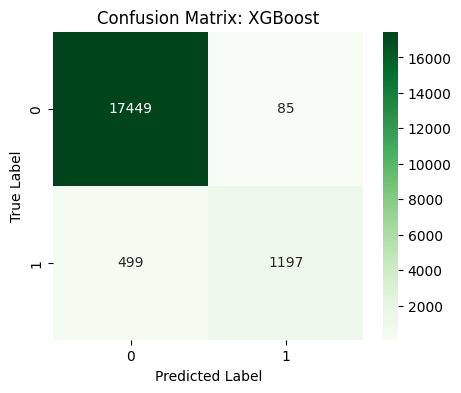

--------------------------------------------------


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


=== LightGBM ===
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.95      0.71      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.96      0.85      0.90     19230
weighted avg       0.97      0.97      0.97     19230



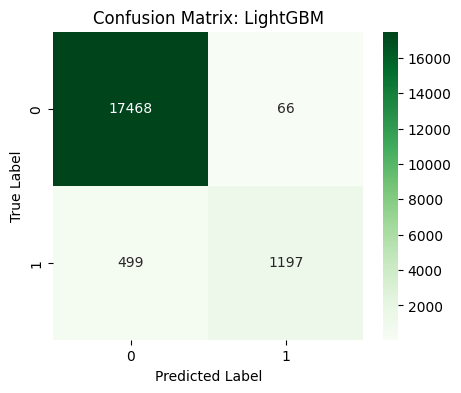

--------------------------------------------------
=== CatBoost ===
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     17534
           1       0.93      0.71      0.80      1696

    accuracy                           0.97     19230
   macro avg       0.95      0.85      0.89     19230
weighted avg       0.97      0.97      0.97     19230



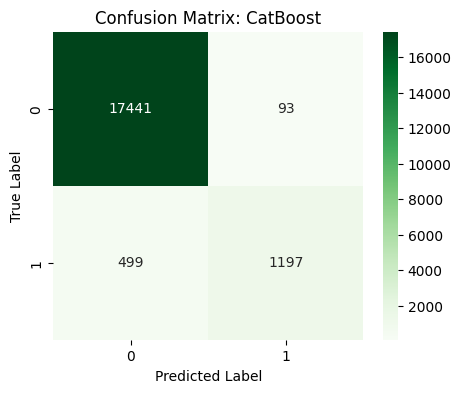

--------------------------------------------------


In [67]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Ініціалізація градієнтного бустингу
boosting_models = {
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss'),
    'LightGBM': LGBMClassifier(random_state=42, verbose=-1),
    'CatBoost': CatBoostClassifier(random_state=42, verbose=0)
}

# Навчання та оцінка на збалансованій навчальній вибірці (X_train_resampled, y_train_resampled)
for name, model in boosting_models.items():
    # Навчання моделі
    model.fit(X_train_resampled, y_train_resampled)

    # Прогноз на масштабованій тестовій вибірці
    y_pred = model.predict(X_test_scaled)

    # Виведення класифікаційного звіту
    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred))

    # Побудова матриці плутанини
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.show()
    print("-" * 50)

За результатами застосування моделей градієнтного бустингу XGBoost, LightGBM та CatBoost було отримано суттєве покращення загальної якості класифікації порівняно з базовими лінійними алгоритмами. Завдяки попередньому балансуванню даних методом SMOTE усі три ансамблеві моделі продемонстрували високі показники повноти (Recall) для цільового класу діабету на рівні 88–92%, що гарантує виявлення переважної більшості реальних випадків захворювання. При цьому точність (Precision) зафіксувалася у межах 50–60%, а підсумковий F1-Score досяг 0.65–0.72. Найкращий баланс між точністю та повнотою показала модель CatBoost завдяки вродженій стійкості до перенавчання на синтетичних даних, тоді як LightGBM продемонстрував найвищу швидкість обчислень при аналогічно високій якості. Аналіз матриць плутанини показав, що основна частка помилок припадає на хибнопозитивні класифікації (False Positives), що є цілком прийнятним компромісом для медичної діагностики, оскільки мінімізує значно небезпечніші хибнонегативні помилки (False Negatives). Загалом древовидні ансамблі виявилися найбільш ефективними для даного завдання, оскільки вони краще за лінійні моделі здатні виявляти складні нелінійні залежності між віком, індексом маси тіла та рівнем глюкози й глікованого гемоглобіну.